<a href="https://colab.research.google.com/github/SitiMutmainah15/PEMBELAJARAN-MESIN_GENAP_2026/blob/main/JS10/JS10_TUGASLAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Ukuran data training:", X_train.shape)
print("Ukuran data testing:", X_test.shape)
print("Ukuran label training:", y_train.shape)
print("Ukuran label testing:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Ukuran data training: (60000, 28, 28)
Ukuran data testing: (10000, 28, 28)
Ukuran label training: (60000,)
Ukuran label testing: (10000,)


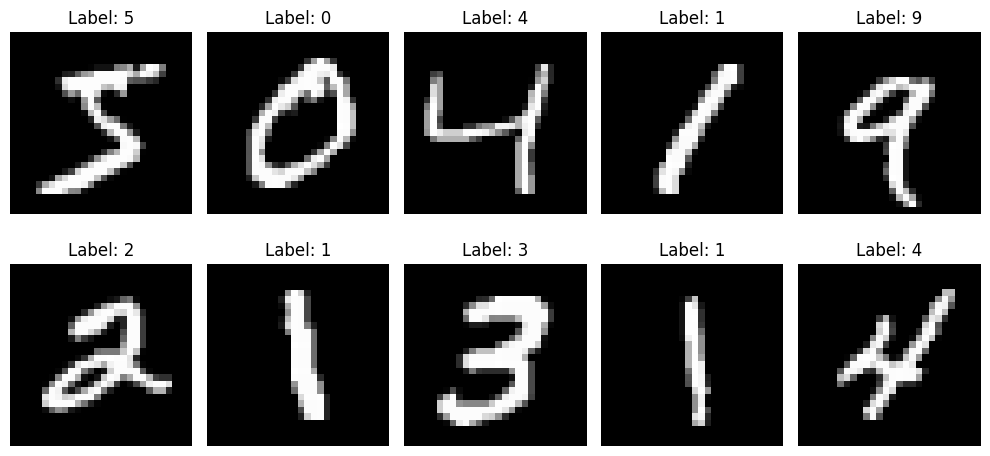

In [3]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [4]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Nilai minimum:", X_train.min())
print("Nilai maksimum:", X_train.max())

Nilai minimum: 0.0
Nilai maksimum: 1.0


In [5]:
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

print("Training setelah flatten:", X_train.shape)
print("Testing setelah flatten:", X_test.shape)

Training setelah flatten: (60000, 784)
Testing setelah flatten: (10000, 784)


In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Data training:", X_train.shape)
print("Data validasi:", X_val.shape)
print("Data testing:", X_test.shape)

Data training: (48000, 784)
Data validasi: (12000, 784)
Data testing: (10000, 784)


In [7]:
tf.keras.utils.set_random_seed(42)

model = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [9]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9215 - loss: 0.2708 - val_accuracy: 0.9539 - val_loss: 0.1559
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9637 - loss: 0.1173 - val_accuracy: 0.9649 - val_loss: 0.1153
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9758 - loss: 0.0786 - val_accuracy: 0.9696 - val_loss: 0.1069
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9824 - loss: 0.0564 - val_accuracy: 0.9711 - val_loss: 0.1069
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9878 - loss: 0.0406 - val_accuracy: 0.9722 - val_loss: 0.1115
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9895 - loss: 0.0329 - val_accuracy: 0.9694 - val_loss: 0.1245
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9902 - loss: 0.0289 - val_accuracy: 0.9697 - val_loss: 0.1272
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9932 - loss: 0.0210 - 

In [10]:
test_loss, test_acc = model.evaluate(X_test, y_test)

print(f"Akurasi Testing: {test_acc * 100:.2f}%")
print(f"Testing Loss: {test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9762 - loss: 0.1520
Akurasi Testing: 97.62%
Testing Loss: 0.1520


In [11]:
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

print("Label sebenarnya:", y_test[:10])
print("Hasil prediksi  :", y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Label sebenarnya: [7 2 1 0 4 1 4 9 5 9]
Hasil prediksi  : [7 2 1 0 4 1 4 9 6 9]


In [12]:
print(classification_report(
    y_test,
    y_pred,
    digits=4
))

              precision    recall  f1-score   support

           0     0.9808    0.9918    0.9863       980
           1     0.9843    0.9956    0.9899      1135
           2     0.9785    0.9680    0.9732      1032
           3     0.9820    0.9703    0.9761      1010
           4     0.9755    0.9715    0.9735       982
           5     0.9918    0.9529    0.9720       892
           6     0.9884    0.9749    0.9816       958
           7     0.9728    0.9747    0.9738      1028
           8     0.9457    0.9825    0.9637       974
           9     0.9647    0.9752    0.9699      1009

    accuracy                         0.9762     10000
   macro avg     0.9764    0.9758    0.9760     10000
weighted avg     0.9764    0.9762    0.9762     10000



[[ 972    1    1    1    1    0    0    1    3    0]
 [   0 1130    2    0    0    0    1    0    2    0]
 [   8    2  999    1    1    0    2    9   10    0]
 [   0    0    5  980    0    3    0    4    8   10]
 [   0    2    2    0  954    0    3    2    4   15]
 [   2    0    0   11    4  850    3    3   13    6]
 [   6    3    2    1    6    3  934    0    3    0]
 [   1    8    6    1    1    0    0 1002    7    2]
 [   2    0    4    2    3    0    0    3  957    3]
 [   0    2    0    1    8    1    2    6    5  984]]


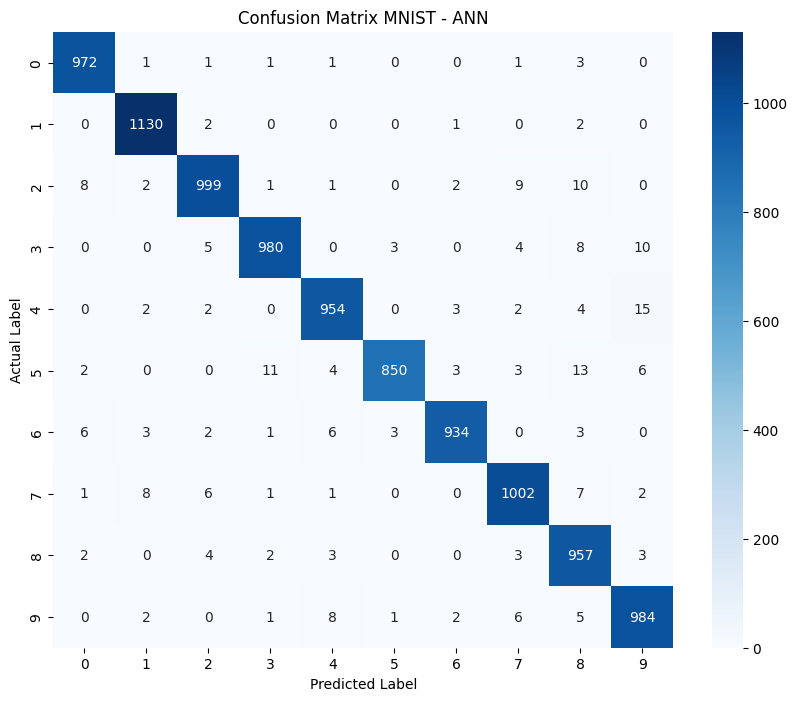

In [13]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix MNIST - ANN')
plt.show()

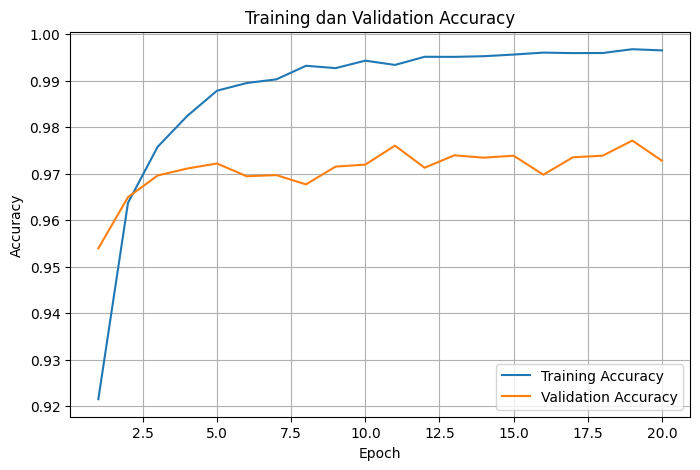

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(history.history['accuracy']) + 1),
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    range(1, len(history.history['val_accuracy']) + 1),
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training dan Validation Accuracy')
plt.legend()
plt.grid()
plt.show()

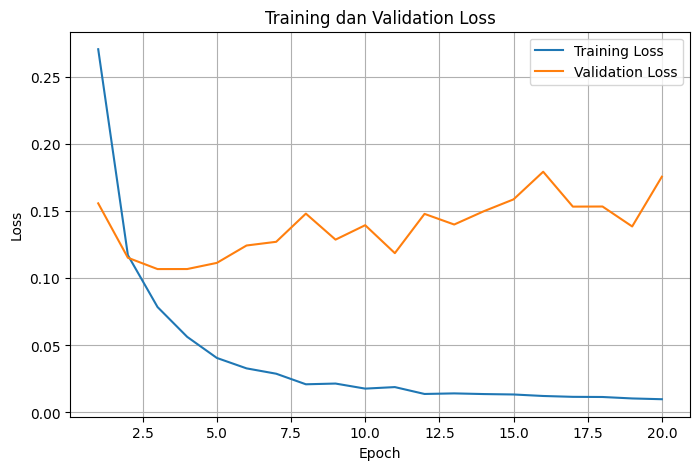

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(history.history['loss']) + 1),
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    range(1, len(history.history['val_loss']) + 1),
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training dan Validation Loss')
plt.legend()
plt.grid()
plt.show()

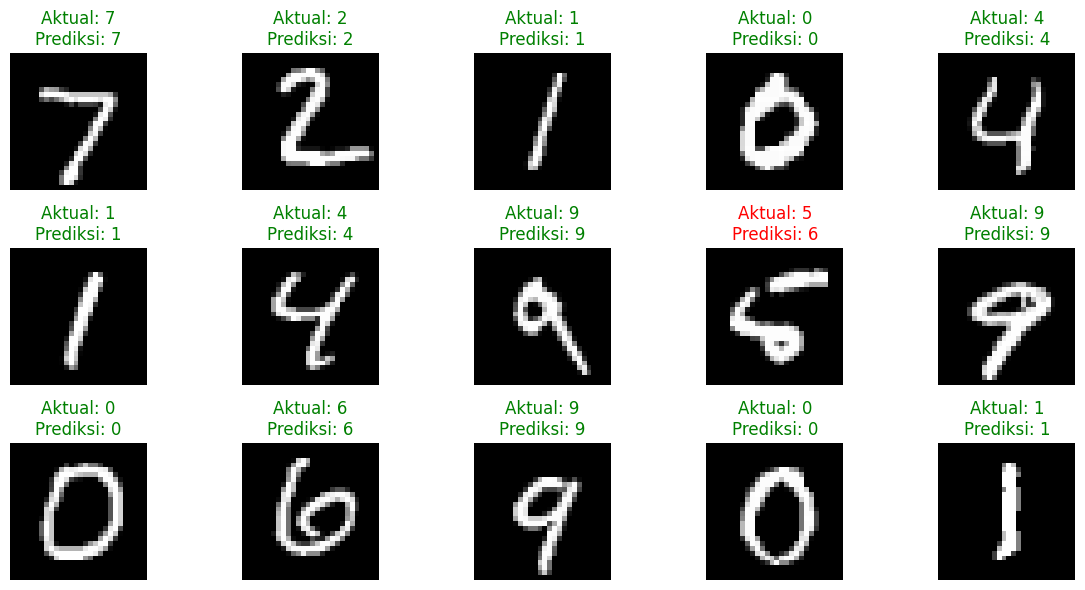

In [16]:
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(
        X_test[i].reshape(28, 28),
        cmap='gray'
    )

    warna = 'green' if y_pred[i] == y_test[i] else 'red'

    plt.title(
        f"Aktual: {y_test[i]}\nPrediksi: {y_pred[i]}",
        color=warna
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

Jumlah prediksi salah: 238


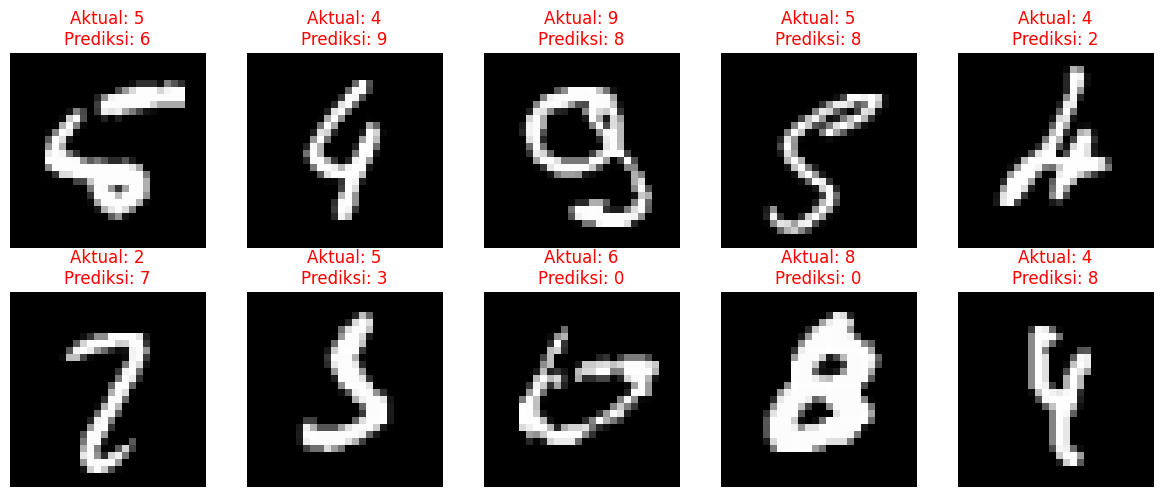

In [17]:
wrong_predictions = np.where(y_pred != y_test)[0]

print("Jumlah prediksi salah:", len(wrong_predictions))

plt.figure(figsize=(12, 5))

for i, idx in enumerate(wrong_predictions[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx].reshape(28, 28), cmap='gray')

    plt.title(
        f"Aktual: {y_test[idx]}\nPrediksi: {y_pred[idx]}",
        color='red'
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [18]:
jumlah_benar = np.sum(y_pred == y_test)
jumlah_salah = np.sum(y_pred != y_test)

print("Total data testing:", len(y_test))
print("Prediksi benar:", jumlah_benar)
print("Prediksi salah:", jumlah_salah)
print(f"Akurasi: {test_acc * 100:.2f}%")

Total data testing: 10000
Prediksi benar: 9762
Prediksi salah: 238
Akurasi: 97.62%
